# 03 · Tokens, context windows and sampling dials, in a graph
Level L1 · Part 1 · core · ~20 min · builds on 02

## Goal
Count the tokens of a policy with the model's own counter, price a call, and see how much of the context window it uses.
Then see the two dials: the thinking budget on the real model, and temperature on a toy sampler. Each dial is a setting on
the same node from lesson 02. The toy sampler stands in for temperature: this lesson does not ask the model for the scores
behind its words, so the maths is shown on made-up scores.

## Why it matters
A budget built on the number of characters is a guess, and a wrong one. The model reads tokens, which are chunks of text
that depend on the model's own tokenizer. A call also has two limits: the input must fit the context window, and the output
has its own cap that the hidden thinking counts against.

| Without counting | With the model's counter |
|---|---|
| Cost is estimated from characters, and is off by an unknown amount | The counter gives the tokens the model will read |
| Thinking looks free, because the answer is short | Thinking is billed as output, and the reply's usage shows it |
| The same temperature is assumed for every task | Each dial is set on purpose, and the change is measured |

**What it makes easy:** a bill you can predict before the call. **When you don't need it:** a short prompt where the cost
does not matter.

## The idea
A **token** is a chunk of text. The **context window** is the room a call has for input. A **sampling dial** decides how the
model picks each next token. **Temperature** sharpens the choice at low values and flattens it at high values. The
**thinking budget** is how many tokens the model may spend thinking before it answers. The thinking tokens are billed as
output, and they are not shown. **Output tokens already include the thinking tokens**, so the output count is the bill for
both the thinking and the answer.

## Picture
The same node runs twice, with different settings. Only the settings change; the graph does not.

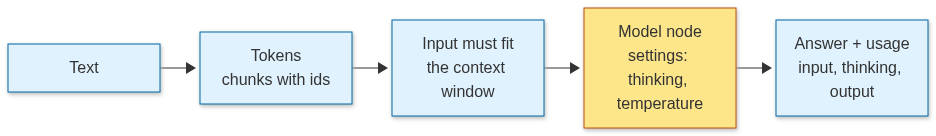

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid  # course helper: draws a Mermaid diagram of the flow

show_mermaid("""
flowchart LR
  T["Text"] --> K["Tokens<br/>chunks with ids"]
  K --> W["Input must fit<br/>the context window"]
  W --> M["Model node<br/>settings: thinking, temperature"]
  M --> O["Answer + usage<br/>input, thinking, output"]
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M model
  class T,K,W,O code
""")

## Step by step
**Step 1 · setup (one model for the lesson).** The key is read from `.env`, never typed here. `llm_replay` (course helper)
saves the answers the first time, so later runs need no key. `get_llm` (course helper, the shared model setup) takes the
settings as keyword arguments, so each dial is set in one place.

In [2]:
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("03_tokens-context-sampling")

from langchain_core.messages import HumanMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from llm_setup import get_llm  # course helper: the shared model setup (Gemini on Vertex AI)
from graph_view import show_graph  # course helper: draws a compiled LangGraph graph

llm = get_llm()  # the default settings, used by the counter in Step 2
PRICE_IN, PRICE_OUT = 0.25, 1.50    # USD per 1M tokens, the same prices as lesson 02
CONTEXT_LIMIT = 1_048_576           # input tokens the model accepts, from its model page

POLICY = """Brightside Outfitters returns policy (made up for this lesson).
Items can be returned within 30 days of delivery. The item must be unused, in its original packaging, and with the tags on.
Start a return from your order page; we send a prepaid label by email within one working day. Refunds go back to the original
payment method within 5 to 10 working days after the returned parcel is scanned at our warehouse. Delivery charges are not
refunded unless the item arrived damaged or the wrong item was sent. Sale items marked final sale cannot be returned. Gift
cards are not refundable; we issue store credit instead. For a lost parcel, contact the desk after 10 working days from
dispatch; we will trace the parcel or send a replacement or refund once the carrier confirms the loss."""

LLM mode: replay (03_tokens-context-sampling.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 2 · count the tokens (the counter, not a guess).** The character guess uses a rule of thumb of four characters per
token. The model's own counter gives the number the model will actually read. `get_num_tokens` sends the text to the model's
count endpoint, which returns a number and writes no answer. It is not a generation, so it is not one of the course's model
calls, which count answers only.

In [3]:
guess = len(POLICY) // 4
counted = llm.get_num_tokens(POLICY)
print(f"characters: {len(POLICY)} · character guess: {guess} tokens · model's counter: {counted} tokens")
print(f"the policy uses {counted / CONTEXT_LIMIT:.4%} of the {CONTEXT_LIMIT:,}-token input limit")

characters: 782 · character guess: 195 tokens · model's counter: 168 tokens
the policy uses 0.0160% of the 1,048,576-token input limit


**Step 3 · the thinking dial, on the real model (2 model calls).** Two graphs run the same question: budget 0 (no thinking
where the model allows it), and a budget of 2,048 tokens. Each reply's usage shows the thinking tokens and the cost. Output
tokens already include thinking, so in the high run below, output 270 includes 247 thinking tokens, and the reply text is
about 23 tokens. The answer should be the same, so the bill is what you compare.

In [4]:
class DialState(MessagesState):
    cost: float


def make_graph(thinking_budget: int):
    model = get_llm(thinking_budget=thinking_budget, max_output_tokens=1024)

    def answer(state: DialState) -> dict:
        reply = model.invoke(state["messages"])
        u = reply.usage_metadata
        thoughts = (u.get("output_token_details") or {}).get("reasoning", 0)
        cost = (u["input_tokens"] * PRICE_IN + u["output_tokens"] * PRICE_OUT) / 1_000_000
        print(f"budget {thinking_budget:>5}: input {u['input_tokens']} · output {u['output_tokens']} "
              f"(thinking {thoughts}) · ${cost:.6f}")
        return {"messages": [reply], "cost": cost}

    g = StateGraph(DialState)
    g.add_node("answer", answer)
    g.add_edge(START, "answer").add_edge("answer", END)
    return g.compile()

Now ask the same question of both graphs. Each prints its usage line, then the first line of its answer.

Gemini on Vertex AI · API key loaded: True
Gemini on Vertex AI · API key loaded: True


budget     0: input 48 · output 20 (thinking 0) · $0.000042
 low answer: $30
budget  2048: input 48 · output 270 (thinking 247) · $0.000417
high answer: $30


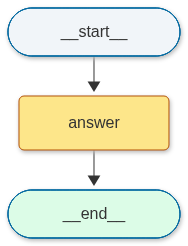

In [5]:
QUESTION = ("Order 1093 cost $84 including $6 delivery. The customer returns the $30 item and keeps the rest. "
            "Delivery is not refunded. How much is refunded? Answer with the number and one line of working.")
low, high = make_graph(0), make_graph(2048)  # 0 turns thinking off where the model allows it
for name, app in (("low", low), ("high", high)):
    final = app.invoke({"messages": [HumanMessage(content=QUESTION)]})
    print(f"{name:>4} answer:", final["messages"][-1].text.strip().splitlines()[0])
show_graph(high, model_nodes=("answer",))

**Step 4 · the sampling dial, on a toy sampler (no call).** No model is needed to see how temperature works. The scores below
are made up for the next word after "Your refund will arrive in ...". They are logits (raw scores). Softmax turns them into
probabilities. Temperature divides each score before softmax: at 0.2 the top word becomes almost certain, at 2.0 the
probabilities spread out. Temperature 0 means always the top word, so the toy cannot use 0.

In [6]:
import math

logits = {"days": 2.0, "weeks": 1.0, "hours": 0.2, "never": -1.5}


def softmax_t(scores: dict, temperature: float) -> dict:
    top = max(v / temperature for v in scores.values())  # subtract the largest for stable maths
    e = {k: math.exp(v / temperature - top) for k, v in scores.items()}
    total = sum(e.values())
    return {k: x / total for k, x in e.items()}


for t in (0.2, 1.0, 2.0):
    print(f"temperature {t}: " + ", ".join(f"{k} {p:.0%}" for k, p in softmax_t(logits, t).items()))

temperature 0.2: days 99%, weeks 1%, hours 0%, never 0%
temperature 1.0: days 64%, weeks 24%, hours 11%, never 2%
temperature 2.0: days 46%, weeks 28%, hours 19%, never 8%


**Step 5 · the settings the course model was built with.** `get_llm` sets the dials in one place: temperature 0 unless a
call passes another value, and an output cap of 1,024 tokens, which thinking counts against. The cell below prints what the
shared `llm` object holds, so you can check a dial before you change it. It also stops the recorder after the last model
call of this lesson.

In [7]:
print(f"temperature: {llm.temperature} · output cap: {llm.max_output_tokens} tokens")
llm_replay.stop()  # the last model call of this lesson

temperature: 0.0 · output cap: 1024 tokens


## At work
- The largest line of a support bill is often the same policy pasted into every call. Teams count tokens per request and cap
  input and output per day → lesson 36 (cost and latency).
- Thinking is billed as output. Teams pick the lowest thinking budget that passes their evals, and check the change with the
  evaluation gate → lesson 32 (evals in CI).
- Low temperature is the usual setting for extraction and tool arguments, because the output must match a schema → lesson 04.

## What just happened
- Step 2: the counter gave 168 tokens for 782 characters, where the character guess said 195.
- Step 3: both graphs answered $30. The high run's output was 270 tokens, of which 247 were thinking, and it cost $0.000417
  against $0.000042 for the low run.
- Step 4: at temperature 0.2 "days" took 99% of the probability; at 2.0 it fell to 46%.
- Step 5: the shared model holds temperature 0 and an output cap of 1,024 tokens.

## Common mistakes
1. **Counting characters as tokens.** The character rule is a guess. This policy has 782 characters: the guess said 195
   tokens, and the model's counter said 168 (Step 2). Count with the counter, as Step 2 does.
2. **Forgetting the thinking tokens.** They count against the output cap and the bill, even though the answer does not show
   them. The high run in Step 3 printed `output 270 (thinking 247)`: most of that output was thinking, not the answer.
3. **A wrong setting type.** A temperature written as a word is refused before the request is sent. Pass a number. The
   cell below prints the first two lines of the error only, because a full traceback shows file paths on this machine.

In [8]:
try:
    get_llm(temperature="hot")  # a word where a number belongs
except Exception as error:
    print(type(error).__name__)
    print("\n".join(str(error).splitlines()[:2]))

ValueError
No model id for gemini: set TUT_LLM_MODEL in .env (see .env.example).


## Try it
A desk expects 2,000 chats a day. Each chat sends the policy (the counter's number from Step 2, which is `counted`) plus 60
tokens of customer message, and gets 150 output tokens back. Work out the cost for 30 days with the prices above. Then add
400 thinking tokens per chat, billed at the output price.

The formula in one line: `cost = chats × (counted + 60) × $0.25 / 1M + chats × 150 × $1.50 / 1M`, with `chats = 2,000 × 30`.
Thinking adds `chats × 400 × $1.50 / 1M`.

In [9]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [10]:
counted = globals().get("counted", 168)  # 168 is the value recorded in Step 2; the fallback keeps this cell running if Step 2 was skipped
chats = 2000 * 30
month_in = chats * (counted + 60)
month_out = chats * 150
base = (month_in * PRICE_IN + month_out * PRICE_OUT) / 1_000_000
extra = chats * 400 * PRICE_OUT / 1_000_000
print(f"per month: ${base:,.2f} · thinking adds ${extra:,.2f}")

per month: $16.92 · thinking adds $36.00


## Key terms
- **Token** — a chunk of text that the model reads and writes, counted by the model's own tokenizer.
- **Context window** — the most input tokens a call can take.
- **Temperature** — the sampling dial that sharpens (low) or flattens (high) the choice of each next token.
- **Thinking budget** — the most tokens the model may spend thinking before it answers; billed as output.
- **Logits** — the raw scores for each candidate next token, before they become probabilities.
- **Softmax** — the function that turns scores into probabilities that add up to 1.

## Recap
- A token is a chunk of text. The model's counter gives the number the model reads.
- The input must fit the context window. The output has its own cap, and thinking counts against it.
- Temperature changes which token is picked; the thinking budget changes how many thinking tokens are billed.
- Set each dial on purpose, and check the bill it changes.

**Interview:** "A teammate says to fix wrong answers by setting temperature to 0. What do you check first?" Strong answer:
"Whether the context has the facts the answer needs, and whether the output cap cuts the answer. Temperature 0 makes the output
steadier, not more correct, so I fix the context and measure the change with evals."